# 04 · Tabelas gerenciadas × não gerenciadas

Item 4 do enunciado: analisar a diferença entre tabelas **gerenciadas** (*managed*) e **não gerenciadas**
(*unmanaged*, também chamadas de **externas**). O experimento é simples: criamos uma tabela de cada tipo
com os mesmos dados (`planos`), olhamos onde os arquivos ficam e vemos o que acontece com eles no `DROP TABLE`.

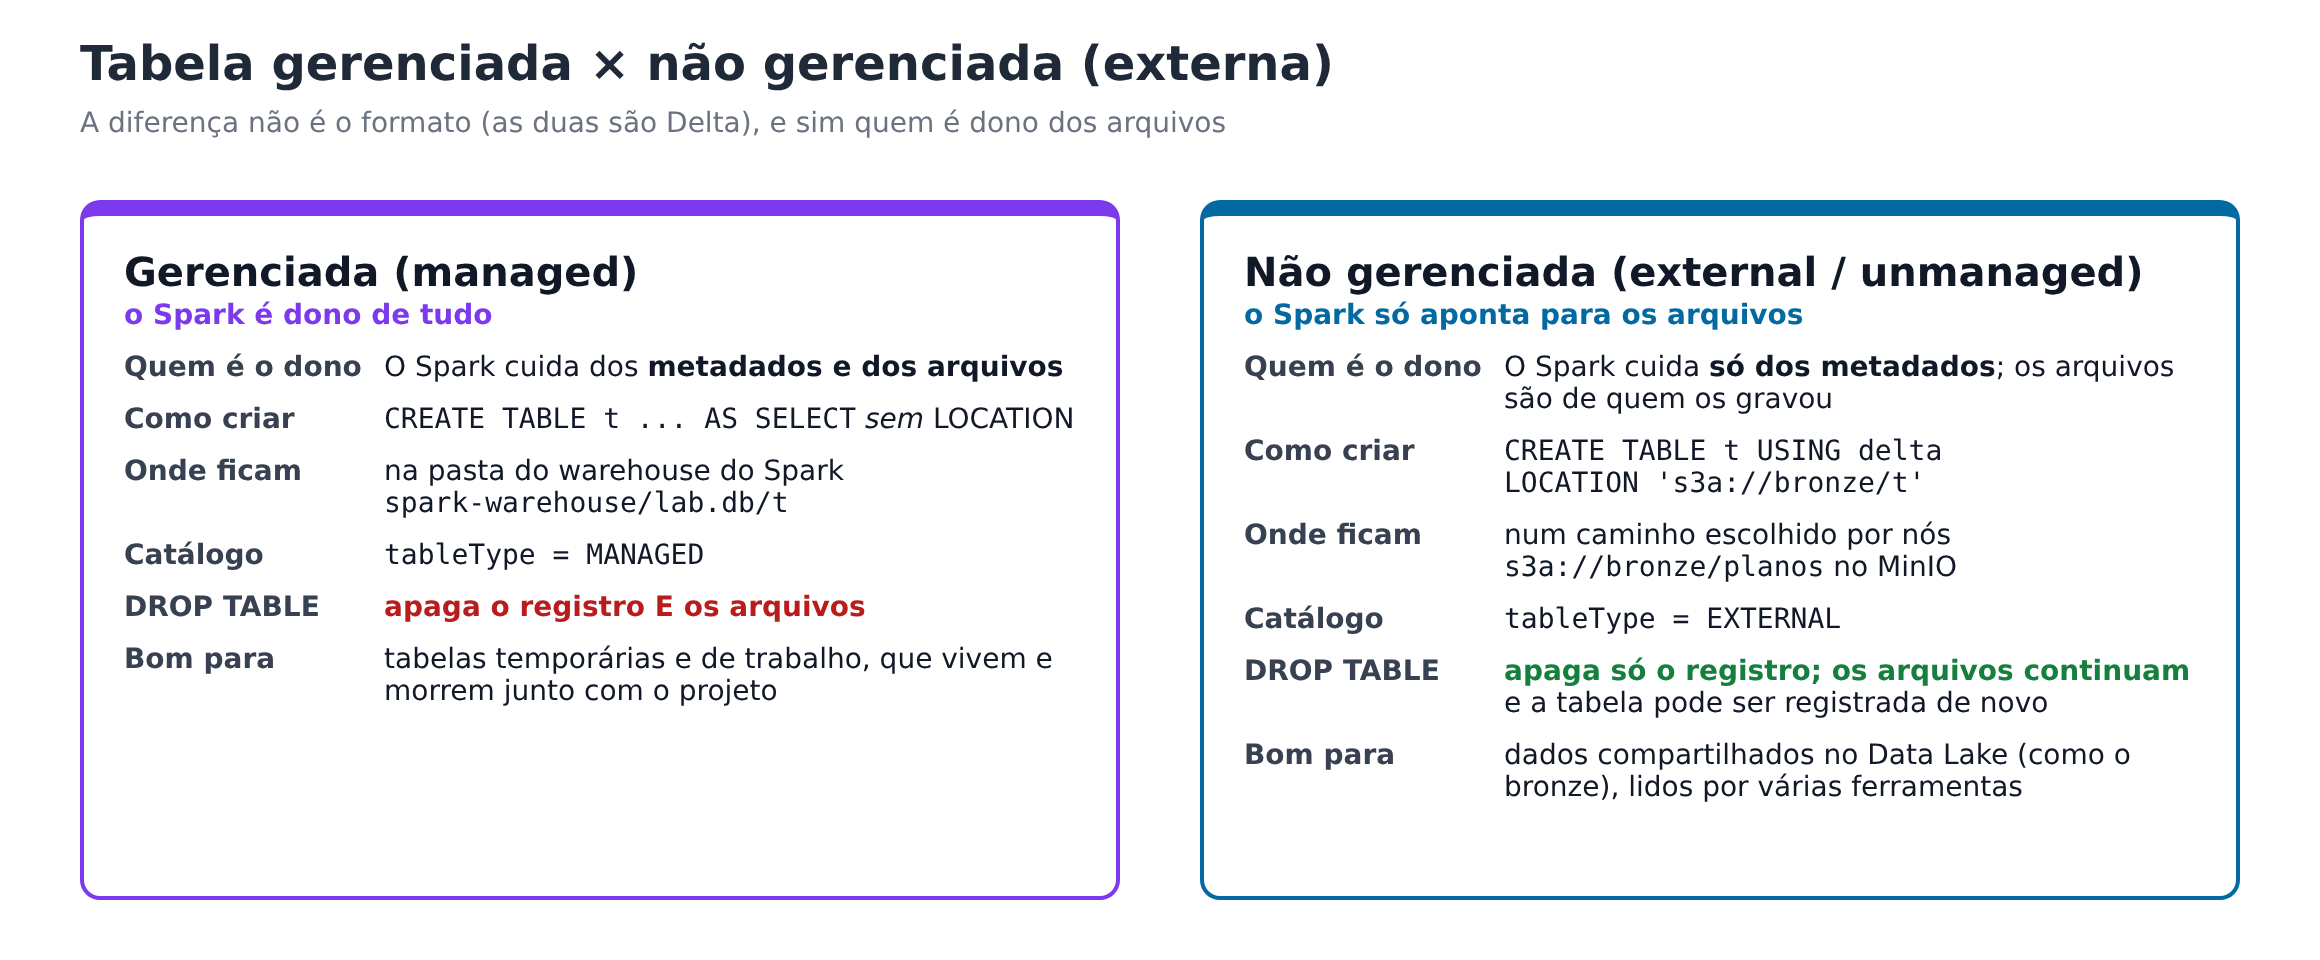

**Antes de rodar:** notebook `02` executado (tabela `planos` no bucket `bronze`).

## 1. Configuração e SparkSession

> **Primeira execução:** o Spark baixa da internet os pacotes `.jar` do Delta Lake e do conector S3A
> (incluindo o SDK da AWS, com cerca de 280 MB). Pode levar alguns minutos. Depois disso fica em cache em `~/.ivy2`.

In [ ]:
import os
from pathlib import Path
from dotenv import load_dotenv

# Raiz do projeto (funciona abrindo o notebook pelo VS Code, pelo JupyterLab ou pelo nbconvert)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / ".env").exists():
    raise FileNotFoundError("Arquivo .env não encontrado. Na raiz do projeto rode: cp .env.example .env")
load_dotenv(ROOT / ".env", override=True)

MINIO_ENDPOINT   = os.getenv("MINIO_ENDPOINT")
MINIO_ACCESS_KEY = os.getenv("MINIO_ACCESS_KEY")
MINIO_SECRET_KEY = os.getenv("MINIO_SECRET_KEY")
LANDING_BUCKET   = os.getenv("MINIO_LANDING_BUCKET")
BRONZE_BUCKET    = os.getenv("MINIO_BRONZE_BUCKET")

import shutil

# Começa do zero: apaga a pasta local onde o Spark guarda as tabelas gerenciadas deste notebook
shutil.rmtree(ROOT / "spark-warehouse" / "lab.db", ignore_errors=True)

In [ ]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("Gerenciadas_vs_Externas")
    .master("local[*]")
    # Delta Lake + conector S3A (para o Spark ler e gravar no MinIO como se fosse o Amazon S3)
    .config("spark.jars.packages", "io.delta:delta-spark_2.12:3.2.0,org.apache.hadoop:hadoop-aws:3.3.4")
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
    .config("spark.sql.warehouse.dir", str(ROOT / "spark-warehouse"))
    .config("spark.driver.memory", "2g")
    # MinIO via S3A
    .config("spark.hadoop.fs.s3a.endpoint", MINIO_ENDPOINT)
    .config("spark.hadoop.fs.s3a.access.key", MINIO_ACCESS_KEY)
    .config("spark.hadoop.fs.s3a.secret.key", MINIO_SECRET_KEY)
    .config("spark.hadoop.fs.s3a.path.style.access", "true")
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark

In [ ]:
import boto3
from botocore.client import Config

s3 = boto3.client(
    "s3",
    endpoint_url=MINIO_ENDPOINT,
    aws_access_key_id=MINIO_ACCESS_KEY,
    aws_secret_access_key=MINIO_SECRET_KEY,
    config=Config(signature_version="s3v4"),
    region_name="us-east-1",
)


def garantir_bucket(nome):
    """Cria o bucket no MinIO se ele ainda não existir."""
    existentes = [b["Name"] for b in s3.list_buckets()["Buckets"]]
    if nome in existentes:
        print(f"Bucket [{nome}] já existe")
    else:
        s3.create_bucket(Bucket=nome)
        print(f"Bucket [{nome}] criado!")


def arquivos_no_minio(prefixo):
    return [o["Key"] for o in s3.list_objects_v2(Bucket=BRONZE_BUCKET, Prefix=prefixo).get("Contents", [])]


def tipo_e_local(tabela):
    print(f"{tabela}: tableType = {spark.catalog.getTable(tabela).tableType}")
    spark.sql(f"DESCRIBE TABLE EXTENDED {tabela}") \
        .filter("lower(col_name) IN ('type', 'provider', 'location')") \
        .show(truncate=False)

## 2. Tabela NÃO gerenciada (externa) — aponta para o bucket `bronze`

Criada com `LOCATION`: o Spark só registra no catálogo **onde** os dados estão. Os arquivos continuam sendo do MinIO.

In [ ]:
spark.sql("CREATE DATABASE IF NOT EXISTS lab")
spark.sql(f"""
    CREATE TABLE lab.planos_externa
    USING delta
    LOCATION 's3a://{BRONZE_BUCKET}/planos'
""")
tipo_e_local("lab.planos_externa")
spark.table("lab.planos_externa").orderBy("id_plano").show()

## 3. Tabela gerenciada — o Spark é dono dos arquivos

Criada **sem** `LOCATION` (aqui com `CREATE TABLE ... AS SELECT`): o Spark decide onde gravar,
dentro da pasta do *warehouse* (`spark-warehouse/` na raiz do projeto).

In [ ]:
spark.sql("""
    CREATE TABLE lab.planos_gerenciada
    USING delta
    AS SELECT * FROM lab.planos_externa
""")
tipo_e_local("lab.planos_gerenciada")

In [ ]:
# O catálogo do Spark mostra o tipo de cada tabela
for t in spark.catalog.listTables("lab"):
    print(f"  {t.name:<20} tableType = {t.tableType}")

## 4. Onde estão os arquivos de cada uma

In [ ]:
pasta_gerenciada = ROOT / "spark-warehouse" / "lab.db" / "planos_gerenciada"
print("Gerenciada -> disco local:", pasta_gerenciada)
for p in sorted(pasta_gerenciada.rglob("*")):
    if p.is_file() and not p.name.endswith(".crc"):
        print("   ", p.relative_to(pasta_gerenciada))

print("\nExterna -> MinIO:", f"s3a://{BRONZE_BUCKET}/planos")
for chave in arquivos_no_minio("planos/"):
    print("   ", chave)

## 5. O teste decisivo: `DROP TABLE`

Apagamos as duas tabelas e conferimos o que sobrou dos arquivos.

In [ ]:
spark.sql("DROP TABLE lab.planos_gerenciada")
print("Gerenciada: a pasta ainda existe?", pasta_gerenciada.exists())

In [ ]:
qtd_antes = len(arquivos_no_minio("planos/"))
spark.sql("DROP TABLE lab.planos_externa")
qtd_depois = len(arquivos_no_minio("planos/"))
print(f"Externa: arquivos no MinIO antes do DROP = {qtd_antes} | depois do DROP = {qtd_depois}")
print("Tabelas que sobraram no catálogo:", [t.name for t in spark.catalog.listTables("lab")])

## 6. A tabela externa pode ser "recuperada"

Como os arquivos continuam no MinIO, basta registrar a tabela de novo. Os dados **e o histórico** (versões dos notebooks 02 e 03)
estão todos lá, porque o `_delta_log` também ficou intacto.

In [ ]:
spark.sql(f"CREATE TABLE lab.planos_externa USING delta LOCATION 's3a://{BRONZE_BUCKET}/planos'")
spark.table("lab.planos_externa").orderBy("id_plano").show()
spark.sql("DESCRIBE HISTORY lab.planos_externa").select("version", "timestamp", "operation").show(truncate=False)

## 7. Verificações automáticas

In [ ]:
checks = {
    "a gerenciada sumiu do disco depois do DROP": not pasta_gerenciada.exists(),
    "a externa manteve os arquivos no MinIO depois do DROP": qtd_depois == qtd_antes and qtd_depois > 0,
    "a externa foi registrada de novo com os mesmos 4 planos": spark.table("lab.planos_externa").count() == 4,
}
for descricao, ok in checks.items():
    print(("  OK    " if ok else "  FALHOU ") + descricao)
assert all(checks.values()), "Alguma verificação falhou (veja acima)."
print("\nTodas as verificações passaram.")

## 8. Conclusão

| | Gerenciada (*managed*) | Não gerenciada (*external*) |
|---|---|---|
| Como criar | `CREATE TABLE ... AS SELECT` sem `LOCATION` | `CREATE TABLE ... LOCATION 's3a://...'` |
| Onde ficam os arquivos | onde o Spark decide (`spark-warehouse/`) | onde nós escolhemos (bucket `bronze` no MinIO) |
| Catálogo (`tableType`) | `MANAGED` | `EXTERNAL` |
| `DROP TABLE` | apaga metadados **e** arquivos | apaga só os metadados; arquivos e histórico ficam |
| Uso típico | tabelas temporárias/de trabalho do próprio Spark | dados compartilhados do Data Lake (camadas bronze, silver, gold) |

Por isso as tabelas do bucket `bronze` foram registradas como **externas** no notebook 03: o dado pertence ao Data Lake,
não a uma sessão do Spark, e apagar uma tabela do catálogo não pode apagar o dado.

In [ ]:
spark.stop()
print("SparkSession encerrada.")